# Phase 3 · Model 5 — Demand breakdown: per zone and per priority

**Goal:** forecast not only *how many* orders arrive next hour (notebook 03) but **where** (order lines
per storage zone A–D) and **how urgent** (orders per priority HIGH / MEDIUM / LOW).

**Why:** "125 orders" helps a little; "50 order lines in Zone C and 25 HIGH orders" tells the warehouse
where to park idle robots and how many to keep free and charged.

**Data:** `data/processed/classical_ml/demand_hourly.parquet` (the same table as notebook 03).

Workflow: 1 Understand → 2 Explore → 3 Target + features → 4 Split → 5 Preprocess → 6 Baseline →
7 Train → 8 Validate & tune → 9 Test once → 10 Save & report.

## Step 1 — Understand the problem

| Question | Answer |
|---|---|
| What do we predict? | 7 numbers per hour: order **lines** in Zone A, B, C, D, and **orders** that are HIGH, MEDIUM, LOW |
| When? | Just before the hour starts (only past hours known) |
| Problem type | Time-series regression, **one model per target** |
| How do we judge it? | **MAE** per target, against "same hour last week" |

(A line is one product in an order; a 2-product order adds a line to each product's zone.)

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project root (the folder that contains data/processed), wherever the notebook runs.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed" / "classical_ml"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60)
print("Data folder:", DATA)

Data folder: H:\ai-warehouse-platform\data\processed\classical_ml


## Step 2 — Explore the data

How demand splits across zones and priorities, and whether the split changes during the day.

lines_zone_a     0.250
lines_zone_b     0.250
lines_zone_c     0.250
lines_zone_d     0.250
orders_high      0.201
orders_medium    0.500
orders_low       0.299
dtype: float64


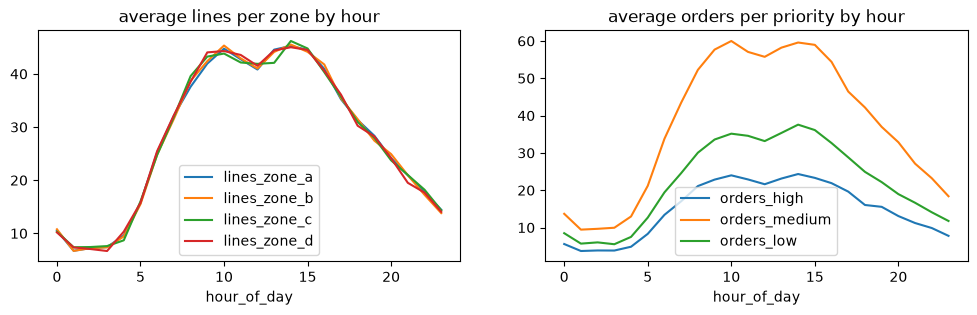

In [2]:
df = pd.read_parquet(DATA / "demand_hourly.parquet").sort_values("timestamp").reset_index(drop=True)
ZONES = ["lines_zone_a", "lines_zone_b", "lines_zone_c", "lines_zone_d"]
PRIORITIES = ["orders_high", "orders_medium", "orders_low"]
TARGETS = ZONES + PRIORITIES
shares = pd.concat([
    (df[ZONES].sum() / df[ZONES].sum().sum()).rename("share of lines"),
    (df[PRIORITIES].sum() / df["orders_total"].sum()).rename("share of orders"),
])
print(shares.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
df.groupby("hour_of_day")[ZONES].mean().plot(ax=ax[0], title="average lines per zone by hour")
df.groupby("hour_of_day")[PRIORITIES].mean().plot(ax=ax[1], title="average orders per priority by hour")
plt.show()

## Step 3 — Choose targets and features

Each target gets its own past-only features, computed the same way as in notebook 03:

- **Calendar:** hour (sine/cosine), weekday, weekend, month, promotion day.
- **The target's own lags:** 1 h, 2 h, 24 h, 168 h ago and the mean of the last 24 h.
- **Total demand lags:** total orders 1 h and 24 h ago (the overall level).

Features have the same names for every target (`lag_1h`, …), so one recipe serves all 7 models.
The first week has no 168 h lag and is dropped.

In [3]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour_of_day"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour_of_day"] / 24)
for col in ["is_weekend", "is_promo_day"]:
    df[col] = df[col].astype(int)
CALENDAR = ["hour_sin", "hour_cos", "day_of_week", "is_weekend", "month", "is_promo_day"]
FEATURES = CALENDAR + ["lag_1h", "lag_2h", "lag_24h", "lag_168h", "rolling_24h_mean",
                       "total_lag_1h", "total_lag_24h"]  # fmt: skip


def features_for(target):
    """Past-only features for one target (the table is in time order, consecutive hours)."""
    y = df[target]
    X = df[CALENDAR].copy()
    for h in (1, 2, 24, 168):
        X[f"lag_{h}h"] = y.shift(h)
    X["rolling_24h_mean"] = y.shift(1).rolling(24).mean()
    X["total_lag_1h"] = df["orders_total"].shift(1)
    X["total_lag_24h"] = df["orders_total"].shift(24)
    return X[FEATURES]


frames = {t: features_for(t) for t in TARGETS}
valid = frames[TARGETS[0]].notna().all(axis=1)
print(f"{valid.sum()} hours with a full week of history (of {len(df)})")

2016 hours with a full week of history (of 2184)


## Step 4 — Split

The same date-based split as all other models: 9 weeks train, 2 validation, 2 test.

In [4]:
split = df["split"]
masks = {s: valid & (split == s) for s in ("train", "validation", "test")}
for s, m in masks.items():
    print(f"{s:10s} {m.sum():5,} hours  {df.loc[m, 'date'].min()} .. {df.loc[m, 'date'].max()}")

train      1,344 hours  2026-09-14 .. 2026-11-08
validation   336 hours  2026-11-09 .. 2026-11-22
test         336 hours  2026-11-23 .. 2026-12-06


## Step 5 — Preprocess

All features are numeric; only the linear model needs scaling (inside its own pipeline).

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Step 6 — Baseline

"Same hour last week" for every target.

In [6]:
from sklearn.metrics import mean_absolute_error


def mae(y_true, y_pred):
    return round(mean_absolute_error(y_true, y_pred), 2)


val_mask, test_mask = masks["validation"], masks["test"]
baseline_val = {t: mae(df.loc[val_mask, t], frames[t].loc[val_mask, "lag_168h"]) for t in TARGETS}
pd.Series(baseline_val, name="baseline validation MAE")

lines_zone_a     6.92
lines_zone_b     6.79
lines_zone_c     6.10
lines_zone_d     6.57
orders_high      4.56
orders_medium    6.51
orders_low       5.15
Name: baseline validation MAE, dtype: float64

## Step 7 — Train models

For every target: Linear Regression, Gradient Boosting and XGBoost.

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor


def candidates():
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Gradient Boosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=42),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, random_state=42),
    }


train_mask = masks["train"]
val_mae, fitted = {}, {}
for t in TARGETS:
    X, y = frames[t], df[t]
    for name, model in candidates().items():
        model.fit(X[train_mask], y[train_mask])
        fitted[(t, name)] = model
        val_mae[(t, name)] = mae(y[val_mask], model.predict(X[val_mask]))
table = pd.Series(val_mae).unstack()
table["Baseline (last week)"] = pd.Series(baseline_val)
table.round(2)

,Gradient Boosting,Linear Regression,XGBoost,Baseline (last week)
lines_zone_a,5.79,5.62,6.28,6.92
lines_zone_b,5.41,5.39,5.37,6.79
lines_zone_c,5.16,5.05,5.15,6.10
lines_zone_d,5.51,5.14,5.57,6.57
orders_high,3.54,3.44,3.54,4.56
orders_low,4.22,4.25,4.15,5.15
orders_medium,5.71,5.51,5.76,6.51


## Step 8 — Validate & choose

For each target the model with the lowest validation MAE is kept (it may differ per target).

In [8]:
best = {t: table.loc[t].drop("Baseline (last week)").idxmin() for t in TARGETS}
pd.DataFrame({"best model": best, "validation MAE": {t: table.loc[t, best[t]] for t in TARGETS}})

,best model,validation MAE
lines_zone_a,Linear Regression,5.62
lines_zone_b,XGBoost,5.37
lines_zone_c,Linear Regression,5.05
lines_zone_d,Linear Regression,5.14
orders_high,Linear Regression,3.44
orders_medium,Linear Regression,5.51
orders_low,XGBoost,4.15


## Step 9 — Test once

Every chosen model on the last 2 weeks, against the baseline, and a plot of the zone forecasts.

,model,test MAE,baseline MAE,improvement %,average per hour
target,,,,,
lines_zone_a,Linear Regression,5.43,6.87,21.0,31.8
lines_zone_b,XGBoost,5.79,7.14,18.9,31.9
lines_zone_c,Linear Regression,4.91,6.31,22.2,31.5
lines_zone_d,Linear Regression,4.73,5.92,20.1,32.0
orders_high,Linear Regression,3.33,4.35,23.4,16.7
orders_medium,Linear Regression,5.49,6.82,19.5,42.8
orders_low,XGBoost,4.17,5.71,27.0,25.3


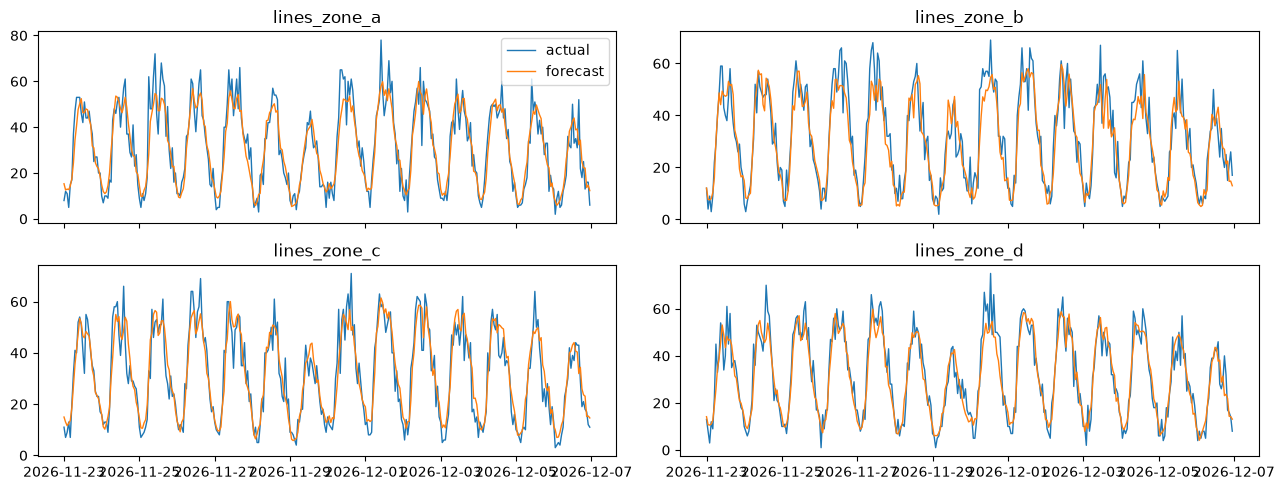

In [9]:
rows = []
preds = {}
for t in TARGETS:
    X, y = frames[t], df[t]
    preds[t] = fitted[(t, best[t])].predict(X[test_mask])
    model_mae = mae(y[test_mask], preds[t])
    base_mae = mae(y[test_mask], X.loc[test_mask, "lag_168h"])
    rows.append({"target": t, "model": best[t], "test MAE": model_mae, "baseline MAE": base_mae,
                 "improvement %": round(100 * (1 - model_mae / base_mae), 1),
                 "average per hour": round(y[test_mask].mean(), 1)})  # fmt: skip
test_table = pd.DataFrame(rows).set_index("target")
display(test_table)

fig, axes = plt.subplots(2, 2, figsize=(13, 5), sharex=True)
for ax, t in zip(axes.ravel(), ZONES, strict=True):
    ax.plot(df.loc[test_mask, "timestamp"], df.loc[test_mask, t], label="actual", lw=1)
    ax.plot(df.loc[test_mask, "timestamp"], preds[t], label="forecast", lw=1)
    ax.set_title(t)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Step 10 — Save & report

All 7 chosen models in one file, with the feature recipe and the average shares (used by the backend before enough history exists).

In [10]:
train_rows = df[masks["train"]]
bundle = {
    "targets": {t: {"model": fitted[(t, best[t])], "algorithm": best[t]} for t in TARGETS},
    "features": FEATURES,
    "share_of_total": {
        **{z: float(train_rows[z].sum() / train_rows["orders_total"].sum()) for z in ZONES},
        **{p: float(train_rows[p].sum() / train_rows["orders_total"].sum()) for p in PRIORITIES},
    },
}
joblib.dump(bundle, MODELS / "demand_breakdown_v1.joblib")
report = {
    "model": "demand_breakdown_v1",
    "dataset_version": "v3",
    "features": FEATURES,
    "validation_mae": {f"{t} | {m}": v for (t, m), v in val_mae.items()},
    "test": test_table.reset_index().to_dict("records"),
}
(MODELS / "demand_breakdown_v1_report.json").write_text(json.dumps(report, indent=2, default=float))
print("Saved models/demand_breakdown_v1.joblib")

Saved models/demand_breakdown_v1.joblib


## Summary

**What we predict:** for the next hour, **order lines per storage zone** (A, B, C, D) and **orders per
priority** (HIGH, MEDIUM, LOW) — seven forecasts, one model each.

**Before (without this model):** only the total was forecast (notebook 03); nothing said *where* the
work would be or *how urgent* it would be. The simple rule "same hour last week" is the baseline.

**Test set (last 2 weeks, incl. Black Friday)**

| Target | Best model | Test MAE | Baseline MAE | Improvement | Average per hour |
|---|---|---|---|---|---|
| lines_zone_a | Linear Regression | 5.43 | 6.87 | 21.0 % | 31.8 |
| lines_zone_b | XGBoost | 5.79 | 7.14 | 18.9 % | 31.9 |
| lines_zone_c | Linear Regression | 4.91 | 6.31 | 22.2 % | 31.5 |
| lines_zone_d | Linear Regression | 4.73 | 5.92 | 20.1 % | 32.0 |
| orders_high | Linear Regression | 3.33 | 4.35 | 23.4 % | 16.7 |
| orders_medium | Linear Regression | 5.49 | 6.82 | 19.5 % | 42.8 |
| orders_low | XGBoost | 4.17 | 5.71 | 27.0 % | 25.3 |

**What it shows**
- Every target is forecast better than "same hour last week"; smaller series (e.g. HIGH orders) are
  noisier, so their error is larger relative to their size.
- Each zone and priority follows the same daily and weekly rhythm as the total, which is why the total's
  recent level (`total_lag_1h`, `total_lag_24h`) helps every model.

**How it is used:** the backend forecasts all seven at the start of each simulated hour (dashboard
"Order lines per zone" and "Orders per priority" bars) and saves each with the real count. In Phase 4
idle robots will be parked near the zone expected to be busiest, and more robots kept free and charged
when many HIGH orders are expected.

**Saved:** `models/demand_breakdown_v1.joblib` (7 models + feature recipe), `models/demand_breakdown_v1_report.json`.